In [1]:
import sys

sys.path.append("..")

import numpy as np
from classes.sample.sample_classes import SingleWaveletPacketSample, SampleWaveletPacket
from classes.signal.signal_classes import WaveletPacket
from classes.sample.raw_data import LMSFile
import matplotlib.pyplot as plt
from scipy.signal import stft
import plotly.express as px
import plotly.graph_objects as go
from datetime import datetime
from pathlib import Path


import json
import scipy
import pandas as pd
import pywt
from tqdm import tqdm
import os
from typing import List, Dict, Any, Tuple, Optional

In [2]:
import matplotlib.pyplot as plt
import scienceplots

plt.style.use(['science','ieee','grid'])


# Get raw files

In [3]:
VALID_START_DATE_S1 = datetime(2023, 1, 16)

In [4]:
metadata = pd.read_csv(Path("../data/metadata/meta_1.csv"))
metadata = metadata.loc[pd.to_datetime(metadata.sampled_at) >= VALID_START_DATE_S1]

In [5]:
def get_indexes(k: int, data: List[float]) -> List[int]:
    data_arr = np.array(data)
    data_max = np.max(data_arr)
    data_min = np.min(data_arr)
    delta = (data_max - data_min) / k
    values = np.arange(data_min, data_max, delta)
    diffs = np.abs(np.subtract.outer(data_arr, values))
    return np.argmin(diffs, axis=0)

In [6]:
avg_tension = metadata[["s1_avg", "s2_avg", "s3_avg", "s4_avg"]].mean(axis=1).to_list()
idx = get_indexes(20, avg_tension)

In [7]:
samples = metadata.iloc[idx]

In [8]:
lms_files = [LMSFile.from_txt(Path(row["path"])) for _, row in samples.iterrows()]

# Compute the sparsity

In [9]:
from lib.wpt_utils import (
    normalize_by_level,
    plot_wpt,
    get_wpt_from_lms,
    combine_wpts,
    get_wpt_arrays,
    build_index_per_level
)

In [10]:
def get_samples_to_target(
    wpt: WaveletPacket, percent: float, level: Optional[int] = None
) -> float:
    level_ind = build_index_per_level(wpt.max_level)[wpt.max_level-1]
    x = np.array(wpt.energy_map)[level_ind]
    x = np.sort(x)[::-1]
    x = x / x.sum()
    xc = np.cumsum(x)
    sample_idx = np.argwhere(xc>percent).reshape(-1)[0]
    return sample_idx / len(xc)

In [11]:
def score_cable_per_level(
    sample_wpt: WaveletPacket, level: int, family: str, percent: float
) -> Dict[int, List[float]]:

    scores_per_cable = []
    for cable in [1, 2, 3, 4]:
        c = combine_wpts(
            [
                getattr(sample_wpt, f"sample_c{cable}").y,
                getattr(sample_wpt, f"sample_c{cable}").z,
            ]
        )
        # score_per_level = [
        #     get_samples_to_target(c, percent=percent, level=l) for l in range(maxlevel)
        # ]
        score = get_samples_to_target(c, percent=percent, level=level)
        #scores_per_cable.append(score_per_level)
        scores_per_cable.append(score)

    return np.array(scores_per_cable)

In [12]:
wavelets = pywt.wavelist()
blocked_wavelets = ["cmor", "gaus", "mexh", "morl", "shan", "cgau", "fbsp", "rbior"]
tension_per_file = []
scores_per_file = []
max_level = 8

for lms_file in tqdm(lms_files):
    tension_per_file.append(
        [np.mean(getattr(lms_file, f"s{i}")) for i in [1, 2, 3, 4]]
    )
    scores_per_wavelet = []
    discrete_wavelets = []
    for w in wavelets:
        if any([w.startswith(bw) for bw in blocked_wavelets]):
            continue
        discrete_wavelets.append(w)
        sample_wpt = get_wpt_from_lms(lms_file, maxlevel=max_level, family=w)
        scores_per_wavelet.append(
            score_cable_per_level(sample_wpt, level=8, family=w, percent=0.99)
        )
    scores_per_file.append(scores_per_wavelet)

  0%|          | 0/20 [00:00<?, ?it/s]c:\Users\eduar\OneDrive\Documentos\Projetos\Doutorado\project\notebooks\..\lib\wpt_utils.py:108: RuntimeWarning: divide by zero encountered in log
  entropy = np.where(p > 0.0, p * np.log(p), 0)
c:\Users\eduar\OneDrive\Documentos\Projetos\Doutorado\project\notebooks\..\lib\wpt_utils.py:108: RuntimeWarning: invalid value encountered in multiply
  entropy = np.where(p > 0.0, p * np.log(p), 0)
100%|██████████| 20/20 [05:33<00:00, 16.70s/it]


In [13]:
scores_array = np.array(scores_per_file)
tension_array = np.array(tension_per_file)

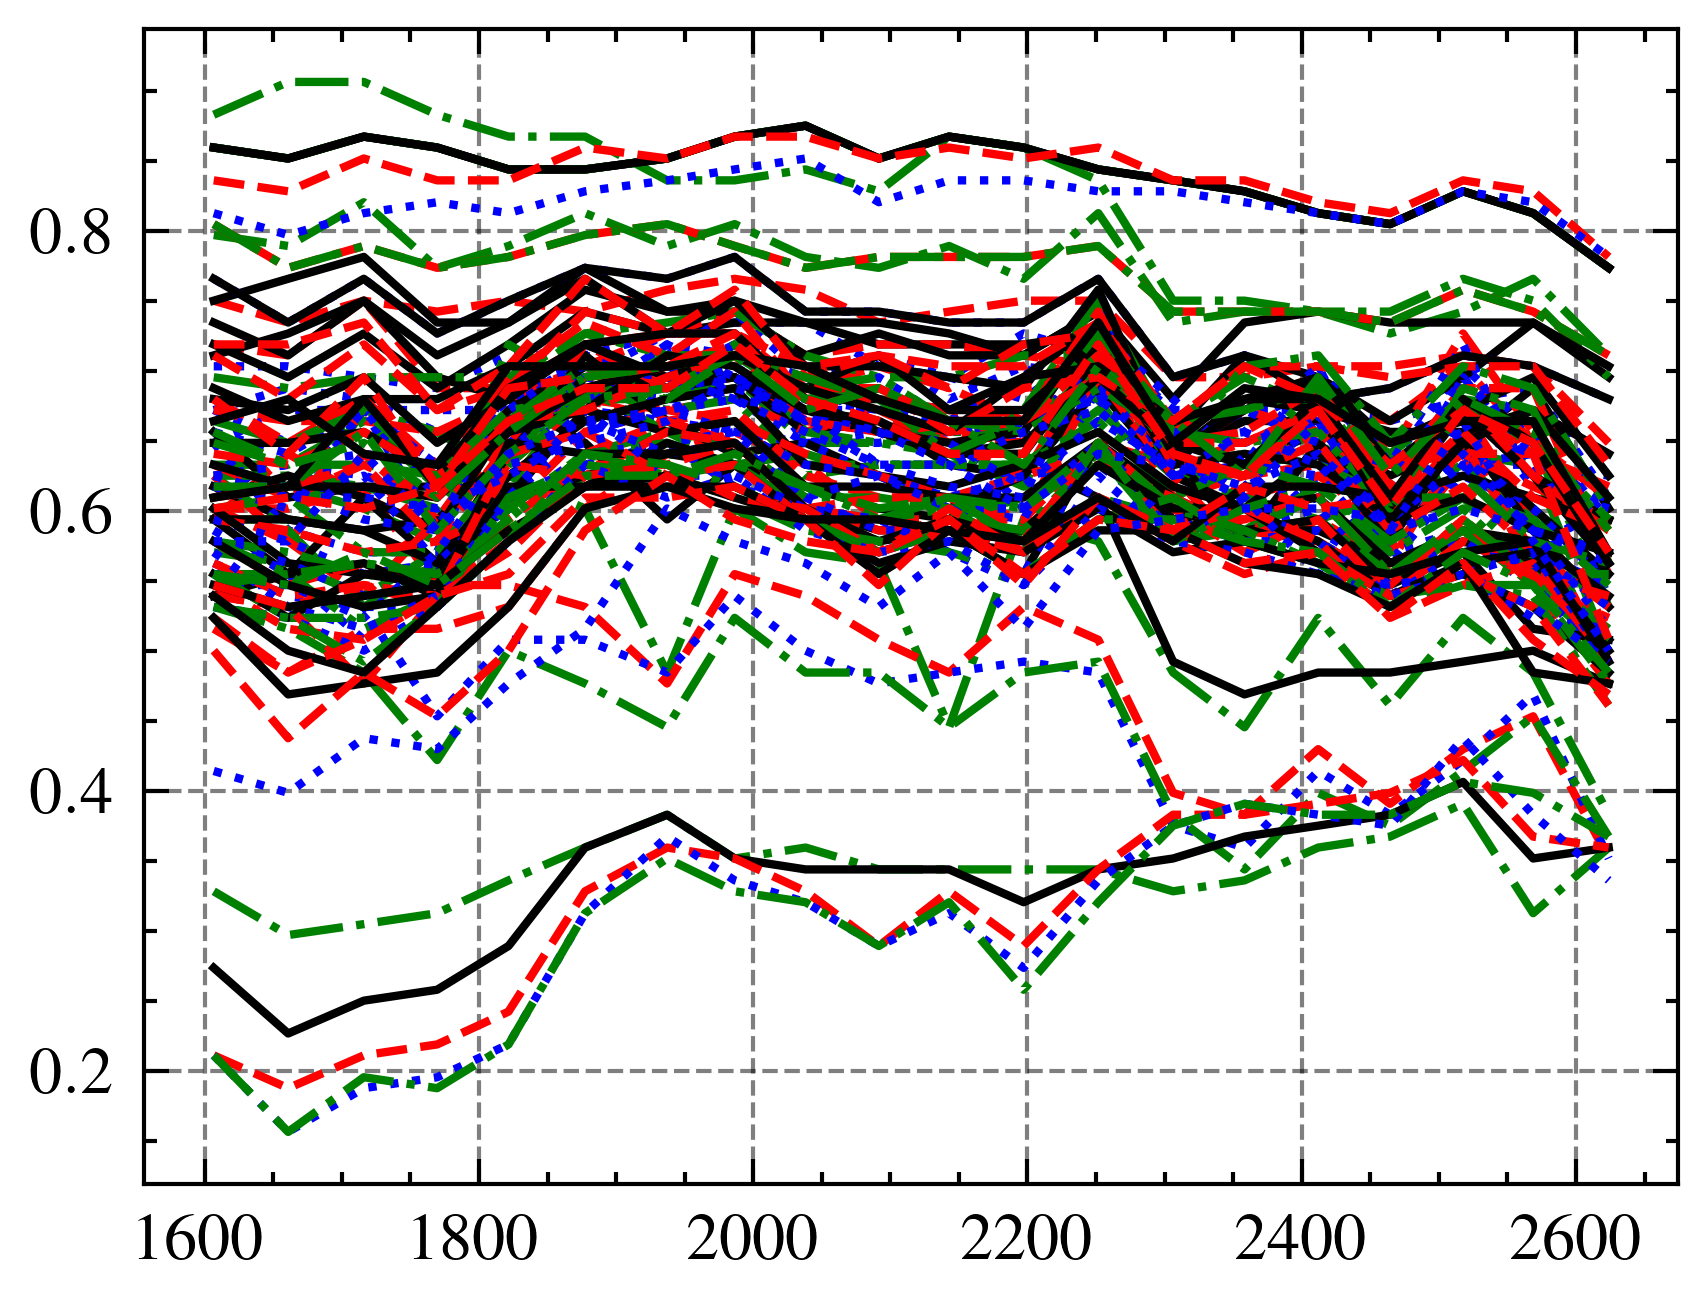

In [14]:
c = 0
for i, w in enumerate(discrete_wavelets):
    t = tension_array[:,c].reshape(-1)
    s = scores_array[:,i,c].reshape(-1)
    plt.plot(t, s)

In [15]:
def wav_to_family(wav: str) -> str:
    if wav.startswith("bior"):
        return "bior"
    if wav.startswith("coif"):
        return "coif"
    if wav.startswith("db"):
        return "db"
    if wav.startswith("sym"):
        return "sym"
    if wav.startswith("rbio"):
        return "rbio"
    else:
        return wav

In [16]:
def get_colormap_colors(cmap_name: str, n: int):
    """
    Returns a list of n RGBA color tuples from the specified Matplotlib colormap.
    
    Args:
        cmap_name (str): Name of the Matplotlib colormap (e.g. 'viridis', 'plasma', etc.).
        n (int): Number of colors to generate.
    
    Returns:
        List[Tuple[float, float, float, float]]: A list of RGBA color tuples.
    """
    cmap = plt.get_cmap(cmap_name)
    return [cmap(i / (n - 1)) for i in range(n)]

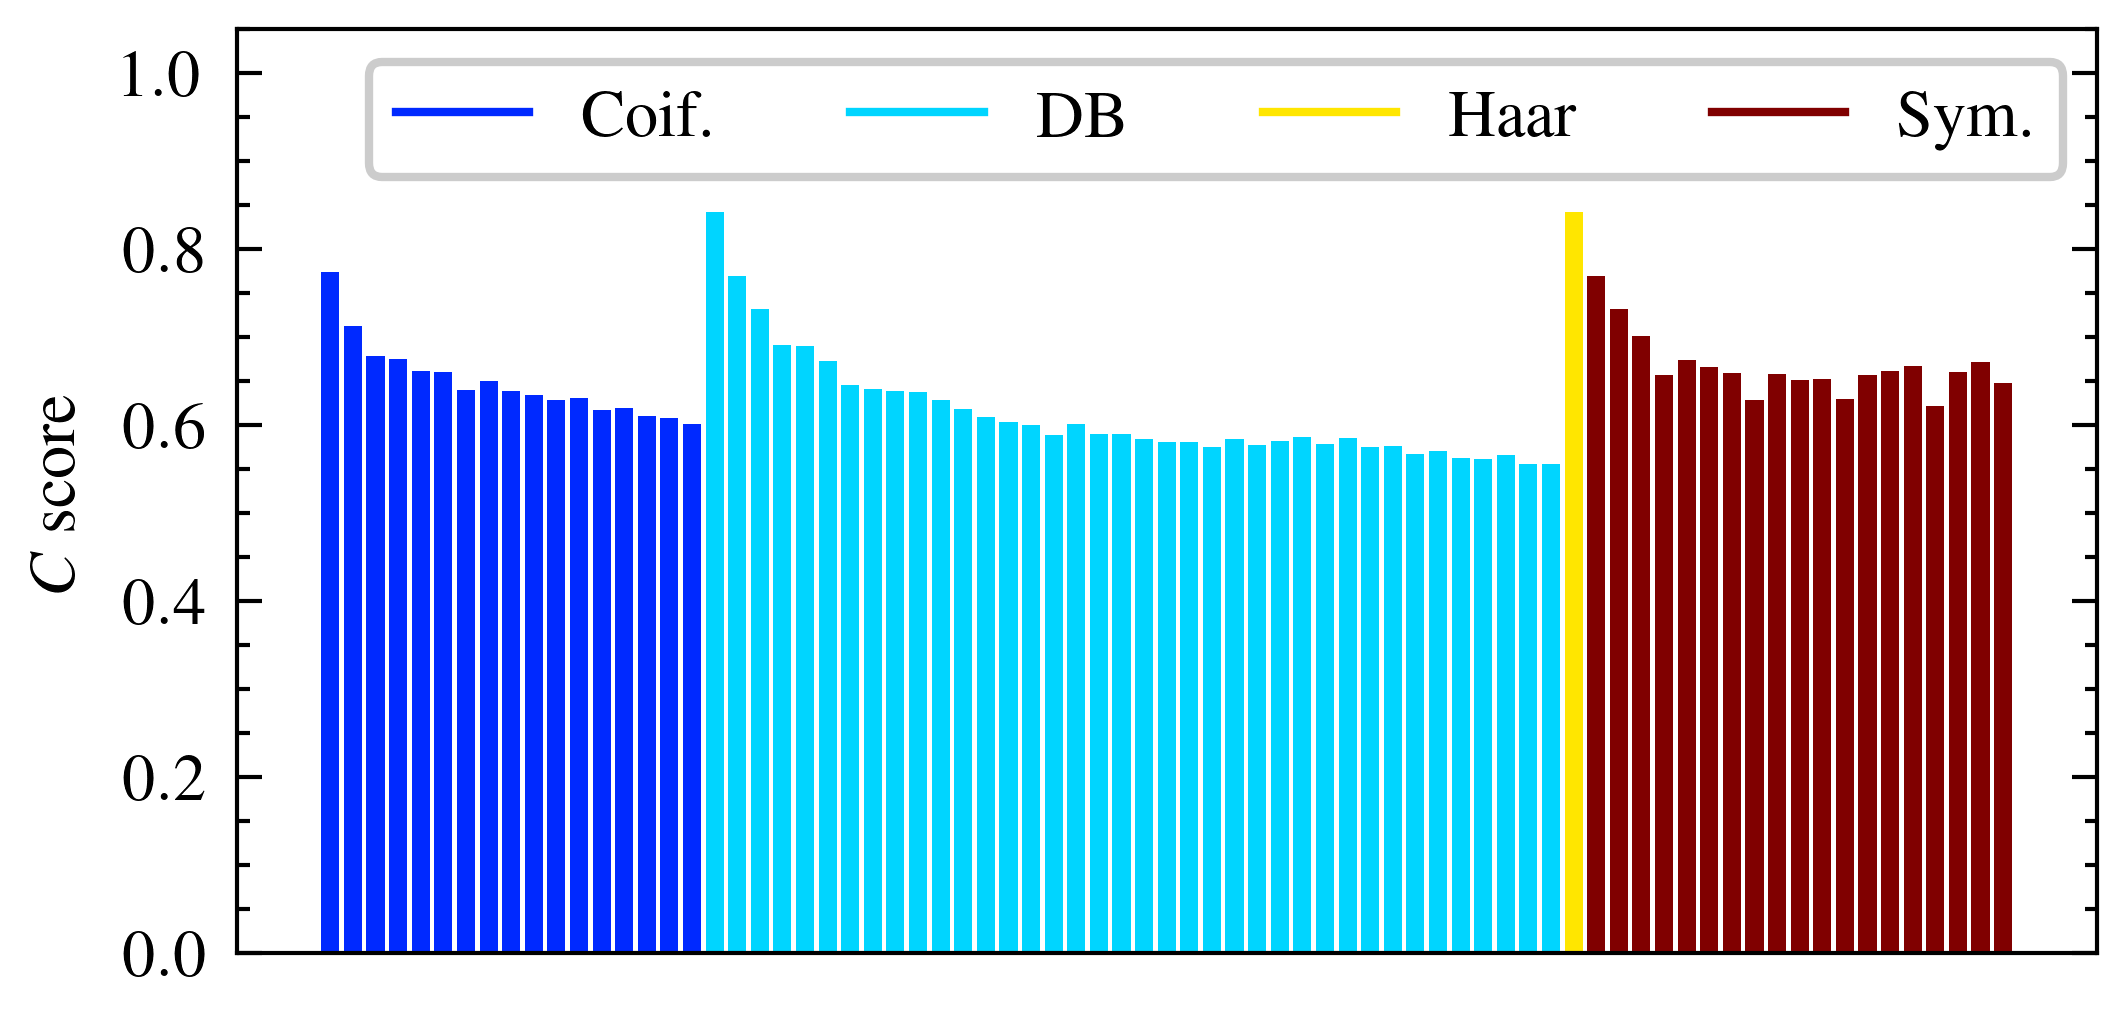

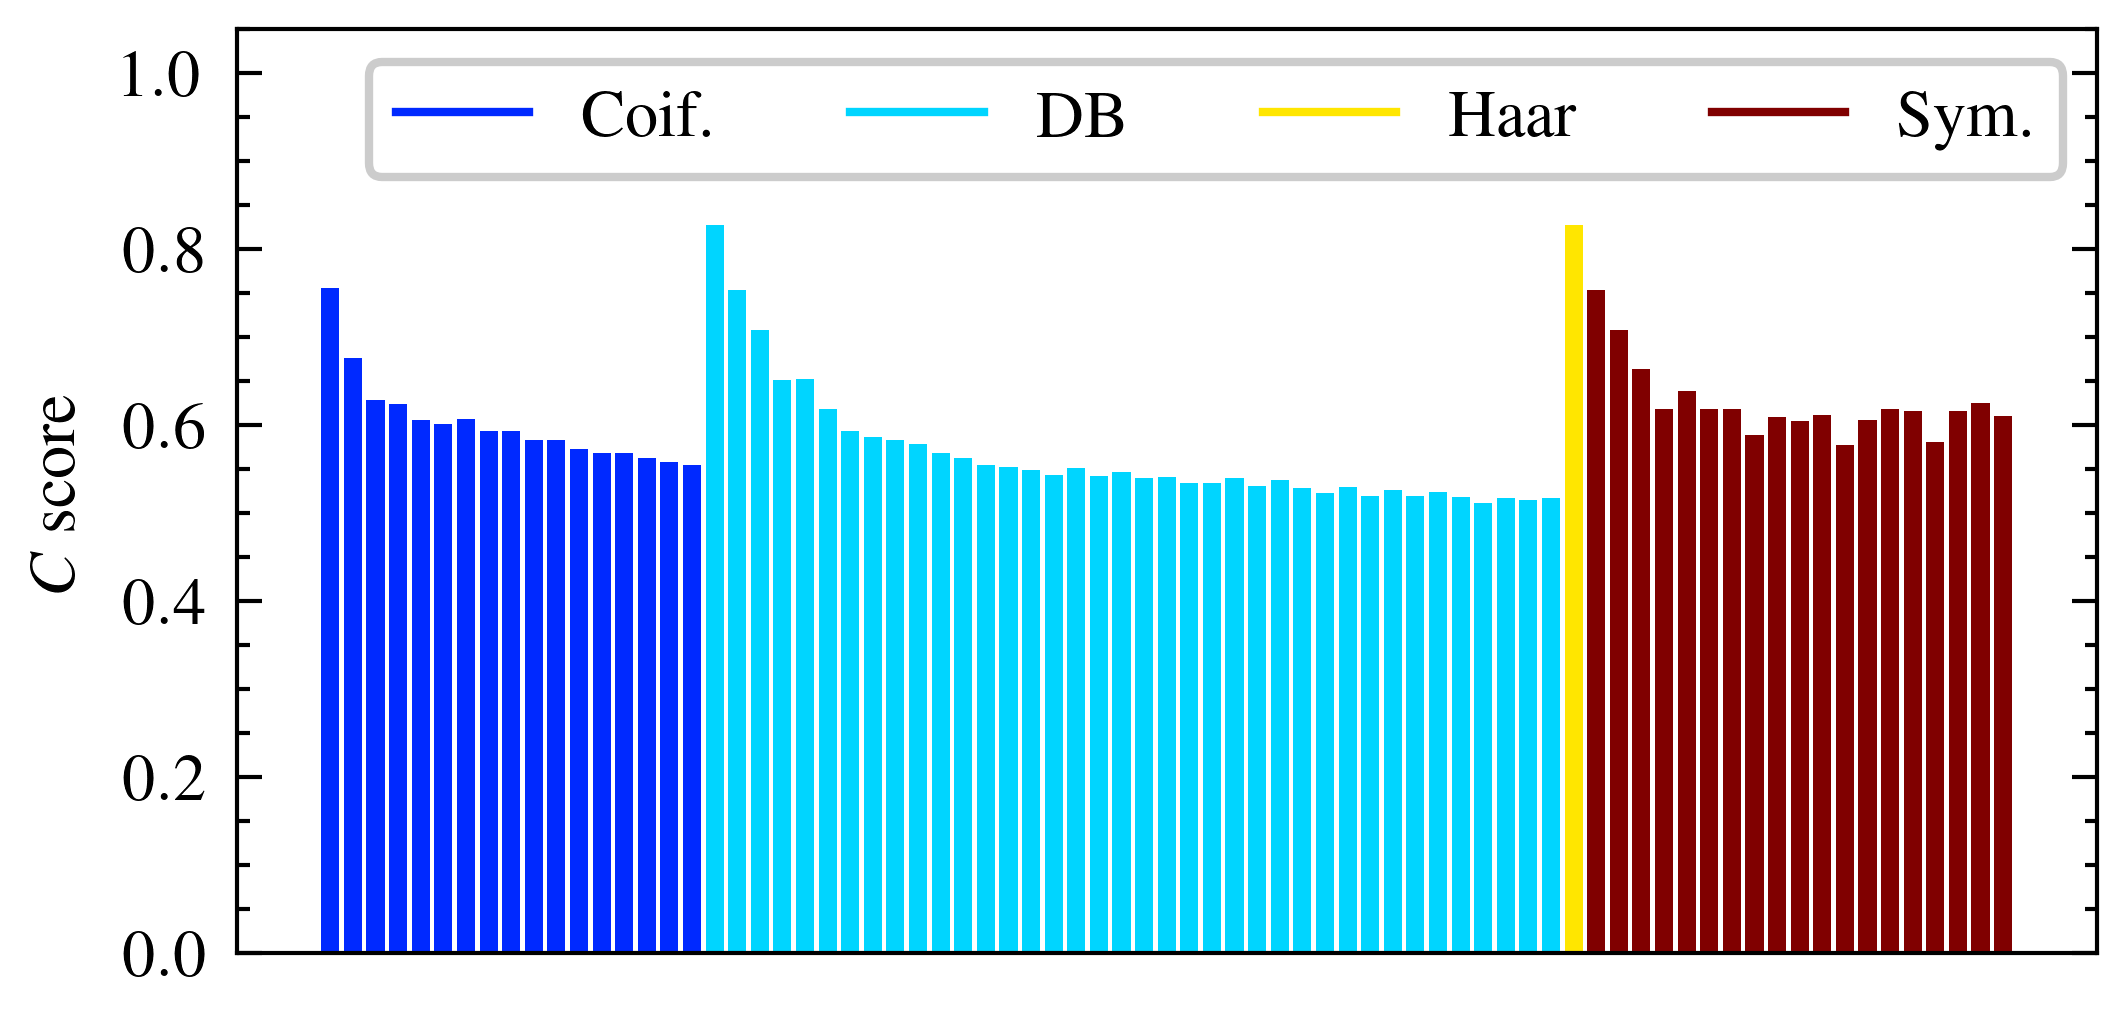

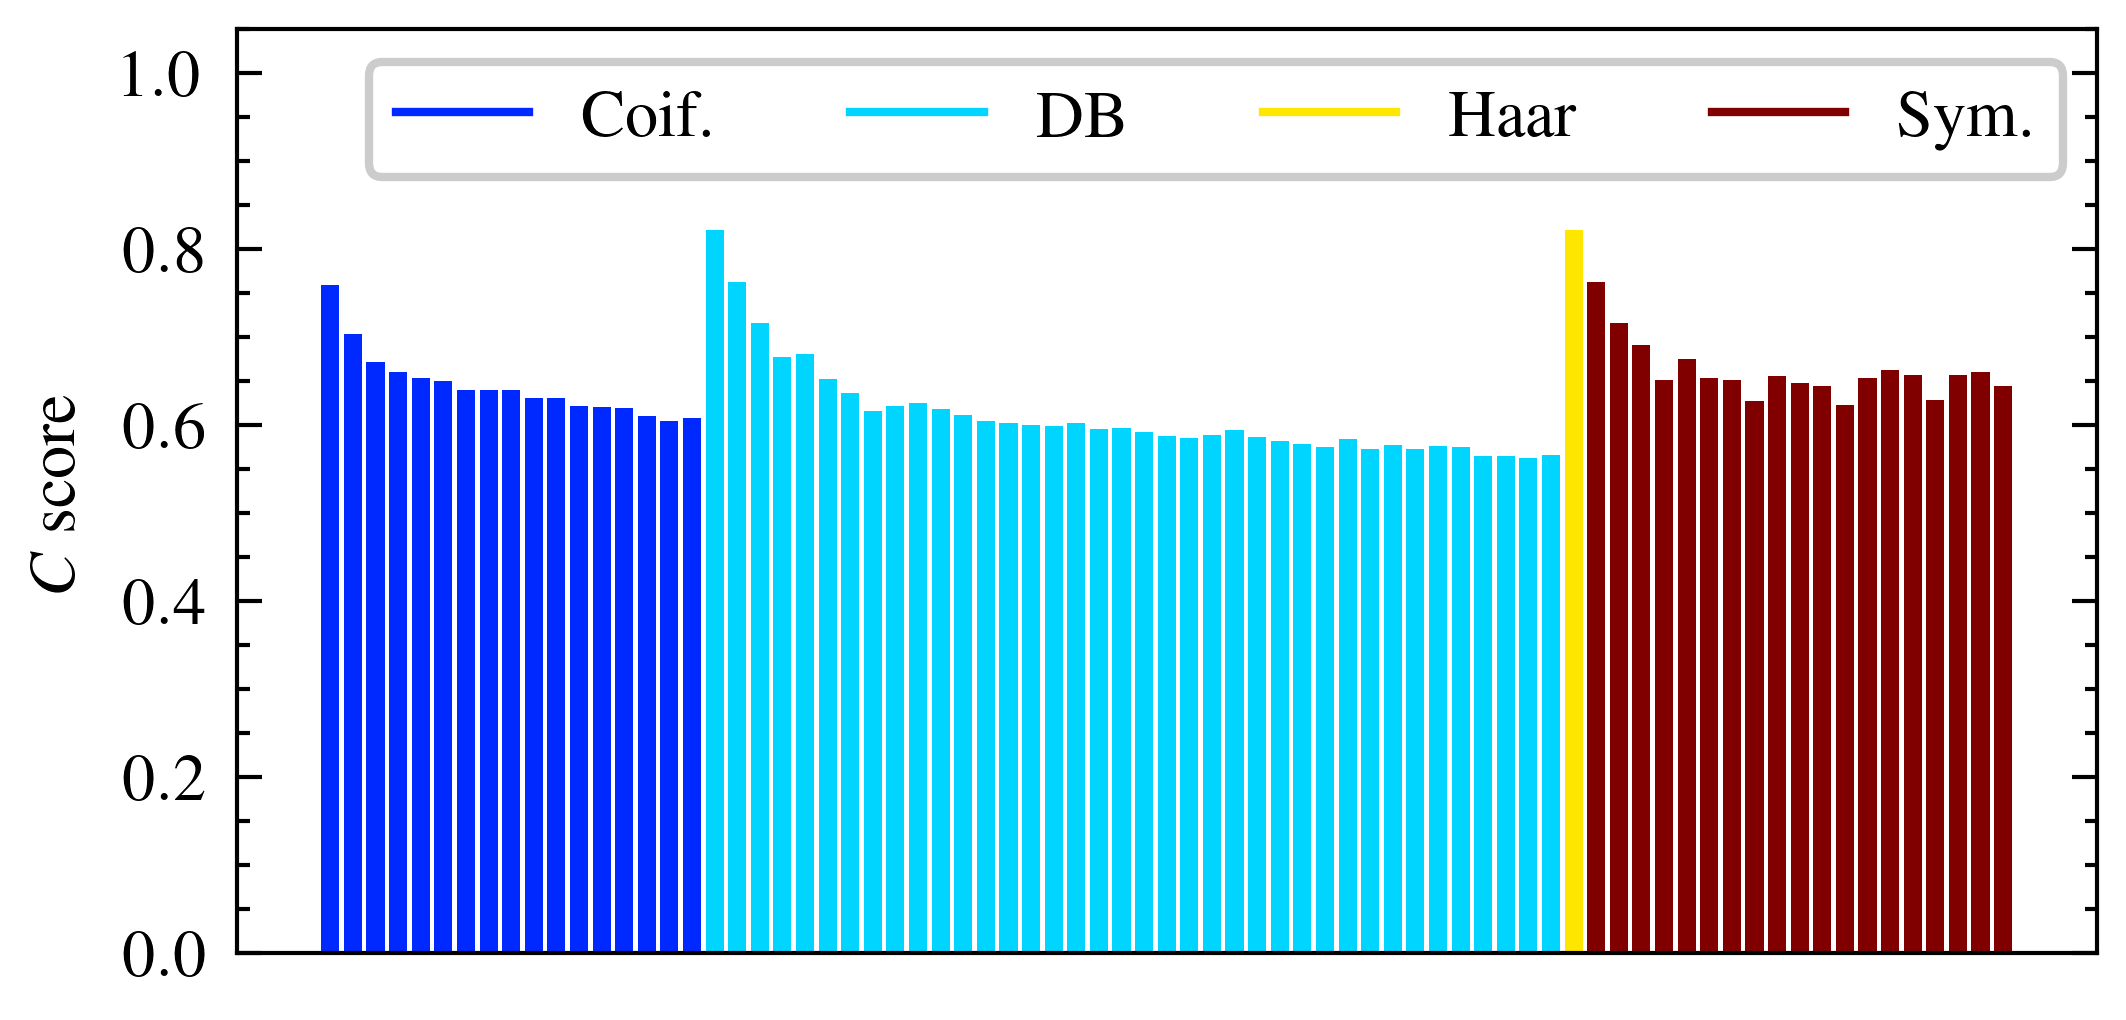

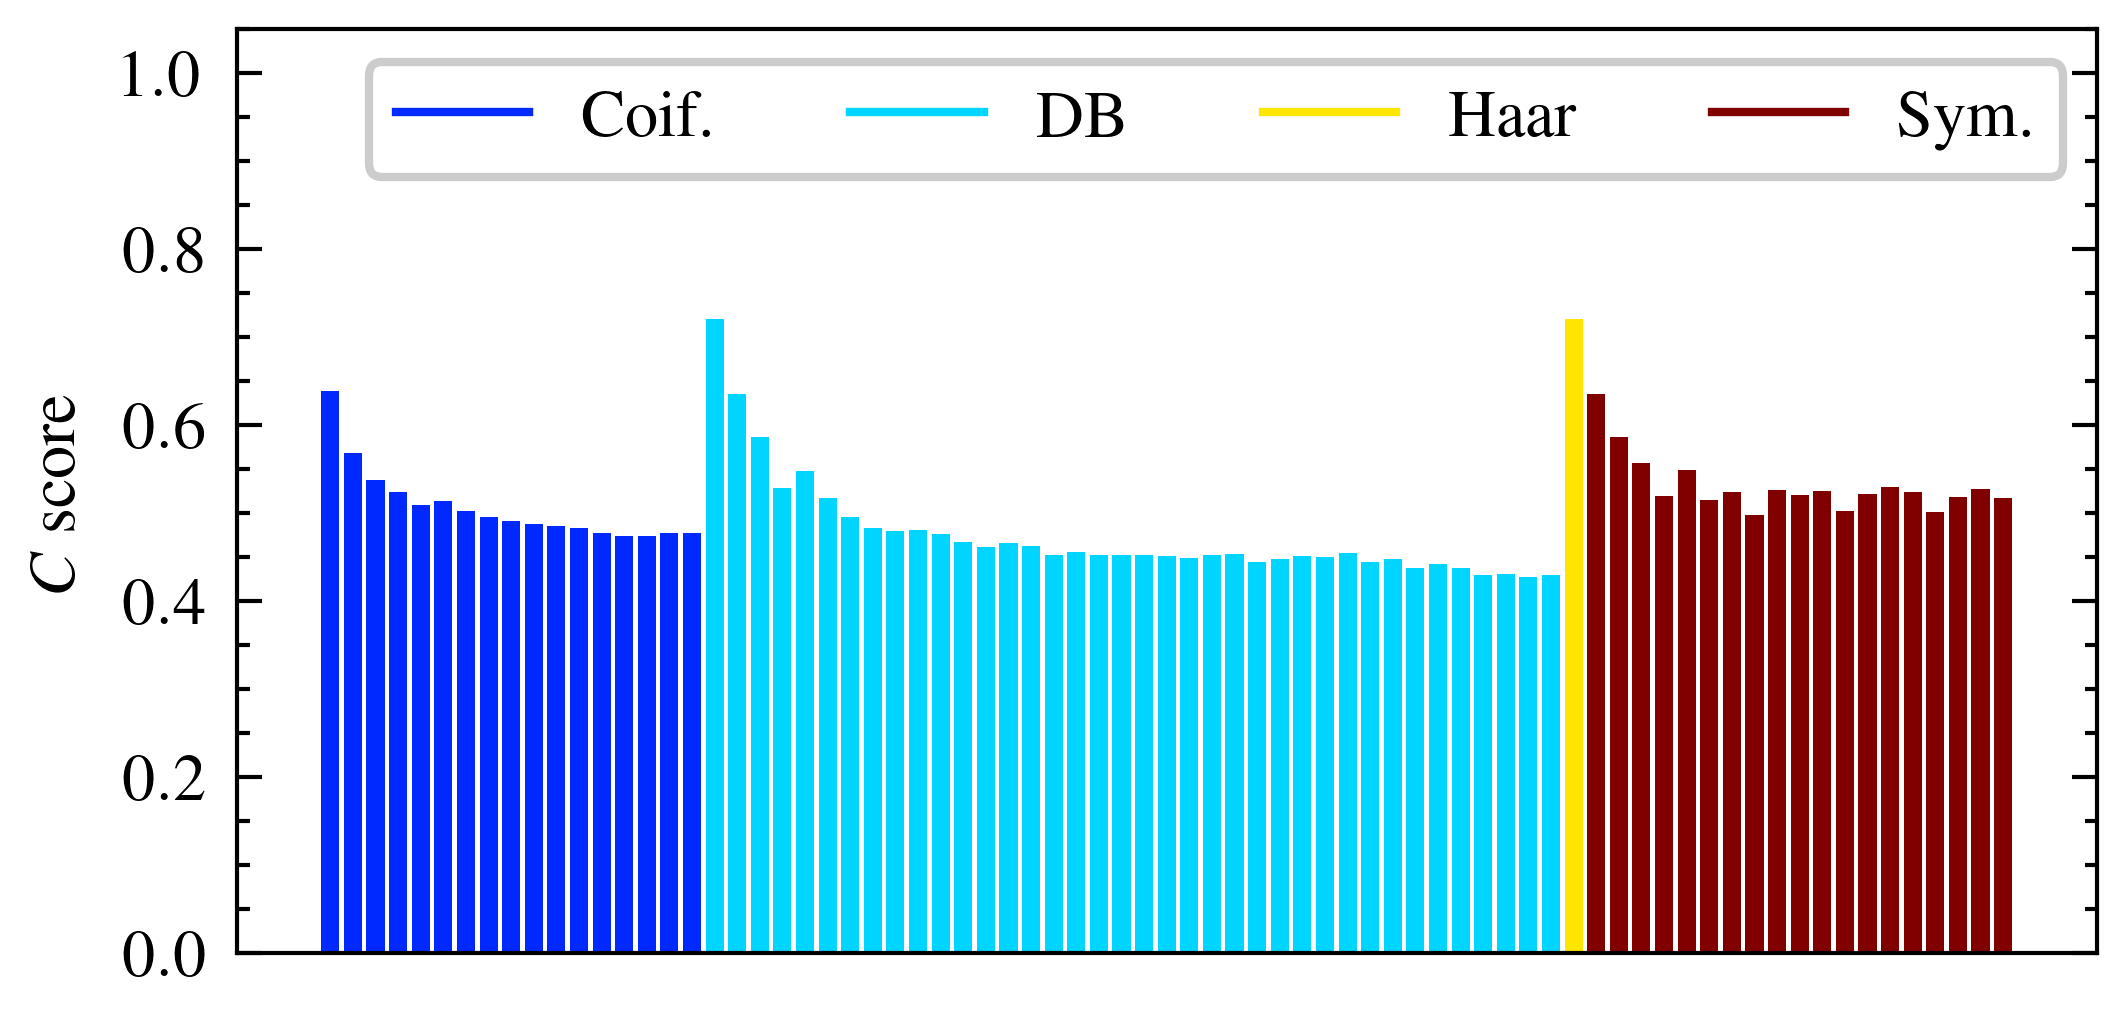

In [17]:
families = [wav_to_family(w) for w in discrete_wavelets]
colors_per_family = {
    np.unique(families)[i]: c
    for i, c in enumerate(get_colormap_colors("jet", len(np.unique(families))))
}
colors = [colors_per_family[wav_to_family(w)] for w in discrete_wavelets]
unique_colors = [colors_per_family[f] for f in np.unique(families)]

families_to_avoid = ["rbio", "bior", "dmey"]
allowed_idx = np.array([f not in families_to_avoid for f in families])

allowed_wavelets = np.array(discrete_wavelets)[allowed_idx]
allowed_colors = np.array(colors)[allowed_idx]

for c in range(4):
    allowed_scores = scores_array.mean(axis=0)[:, c][allowed_idx]
    fig = plt.figure(figsize=(4, 2))
    ax = fig.add_subplot()
    ax.bar(
        x=allowed_wavelets,
        height=allowed_scores,
        color=allowed_colors,
    )
    allowed_families = []
    for f in np.unique(families):
        if f in families_to_avoid:
            continue
        if f == "db":
            allowed_families.append("DB")
        elif f == "coif":
            allowed_families.append("Coif.")
        elif f == "sym":
            allowed_families.append("Sym.")
        elif f == "haar":
            allowed_families.append("Haar")
        col = colors_per_family[f]
        plt.plot([],[], color=col, linestyle="-")
    plt.legend(np.unique(allowed_families), ncols = len(np.unique(allowed_families)))
    # plt.xticks(rotation=90)
    plt.grid(False)
    ax.set_xticks([])  # Remove tick marks
    ax.set_xticklabels([])
    ax.set_ylabel("$C$ score")
    plt.ylim([0, 1.05])
    plt.savefig(f"figures_wpt_results/comparison_cable{c}.png", dpi=300)